# Capstone Part 2 — Dataset + Data Collection

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

In this notebook I find out whether my dataset is good enough for my Capstone project.
I load the data, look at its structure, check its quality and do a first exploratory analysis (EDA).

## 1. Project Question

> **Can early information from an administrative process help us understand which cases are likely to take longer than usual?**

An administrative process is, for example, handling a building-permit application: the application is received,
registered, reviewed, and a decision is sent. Some cases are finished in a few weeks, others take many months.

**Part 2 is only about understanding and evaluating the dataset.** I am not building a predictive model yet.

## 2. Dataset Source and Access

| Item | Information |
|---|---|
| Dataset | **BPI Challenge 2015 — Municipality 1** |
| Creator | Boudewijn van Dongen (Eindhoven University of Technology) |
| Published | 2015, on **4TU.ResearchData** |
| DOI | [10.4121/uuid:a0addfda-2044-4541-a450-fdcc9fe16d17](https://doi.org/10.4121/uuid:a0addfda-2044-4541-a450-fdcc9fe16d17) |
| Terms of use | 4TU General Terms of Use ([doi.org/10.4121/resource:terms_of_use](https://doi.org/10.4121/resource:terms_of_use)), as listed in the dataset's DOI record |
| Content | Building-permit applications from one Dutch municipality |
| Time period | October 2010 – July 2015 (checked in Section 5) |
| Format | XES event log, file `BPIC15_1.xes` |

**Access:** the dataset is public and can be downloaded for free through the DOI link. I saved the file as
`data/raw/BPIC15_1.xes`. The file is not stored on GitHub because it is large and is not my own data.

This is a **public research dataset**. It is **not** SPAR data and not confidential government data.
The analysed event log uses resource identifiers rather than employee names.

## 3. What Does One Row Represent?

The data is an **event log**: a list of the steps that happened in each case.

- **One row = one recorded event** (one step) inside one administrative case.
- **One case = many events.** The same case ID appears on many rows.

Example for one case:

```
Application received → Registration → Review → Decision sent
```

## 4. Load the Dataset

The dataset is stored in **XES event-log format**. I used **PM4Py** to load the XES file and convert the event log into a
**pandas DataFrame** so I could analyse it with Python.

This is the main **data munging** step of the project. Data munging means changing the data into a structure that is easier
to analyse: here, from an XES event log into one table.

In [1]:
import os
import warnings

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
warnings.filterwarnings("ignore")                 # hide an optional speed-up tip from PM4Py

import matplotlib.pyplot as plt
import pandas as pd
import pm4py



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
data_path = "../data/raw/BPIC15_1.xes"

log = pm4py.read_xes(data_path)        # read the XES event log
df = pm4py.convert_to_dataframe(log)   # make sure it is a pandas DataFrame

df.head()

,question,dateFinished,dueDate,action_code,activityNameEN,planned,time:timestamp,monitoringResource,org:resource,activityNameNL,...,case:parts,case:termName,case:endDatePlanned,case:startDate,case:requestComplete,case:IDofConceptCase,case:landRegisterID,case:caseProcedure,case:Includes_subCases,dateStop
0,EMPTY,2014-04-14 00:00:00,2014-04-17 07:30:39+00:00,01_HOOFD_010,register submission date request,2014-04-15 07:30:39+00:00,2014-04-10 22:00:00+00:00,2670601,9264148,registratie datum binnenkomst aanvraag,...,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
1,False,2014-04-14 00:00:00,NaT,01_HOOFD_011,OLO messaging active,2014-04-15 07:34:03+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,OLO berichtenverkeer actief,...,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
2,True,2014-04-14 00:00:00,NaT,01_HOOFD_020,send confirmation receipt,2014-04-15 07:34:03+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,versturen ontvangstbevestiging,...,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
3,False,2014-04-14 00:00:00,2014-04-21 07:37:17+00:00,02_DRZ_010,forward to the competent authority,2014-04-15 07:37:17+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,doorsturen aan bevoegd gezag,...,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
4,True,2014-04-14 00:00:00,NaT,04_BPT_005,regular procedure without MER,2014-04-15 07:37:22+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,reguliere procedure zonder MER,...,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN


Each row is one event. For example, the first rows all belong to the same case and show its first steps.
Columns that start with `case:` describe the whole case, so their value repeats on every row of that case.

In [3]:
first_case = df["case:concept:name"].iloc[0]
df[df["case:concept:name"] == first_case][["case:concept:name", "activityNameEN", "time:timestamp"]].head()

,case:concept:name,activityNameEN,time:timestamp
0,10009138,register submission date request,2014-04-10 22:00:00+00:00
1,10009138,OLO messaging active,2014-04-13 22:00:00+00:00
2,10009138,send confirmation receipt,2014-04-13 22:00:00+00:00
3,10009138,forward to the competent authority,2014-04-13 22:00:00+00:00
4,10009138,regular procedure without MER,2014-04-13 22:00:00+00:00


## 5. Basic Dataset Overview

In [4]:
print("Rows (events):", df.shape[0])
print("Columns:", df.shape[1])
print("Cases:", df["case:concept:name"].nunique())
print("Activity codes (concept:name):", df["concept:name"].nunique())
print("English activity names (activityNameEN):", df["activityNameEN"].nunique())
print("Resources (org:resource):", df["org:resource"].nunique())
print("First event:", df["time:timestamp"].min())
print("Last event:", df["time:timestamp"].max())

Rows (events): 52217
Columns: 29
Cases: 1199
Activity codes (concept:name): 398
English activity names (activityNameEN): 289
Resources (org:resource): 23
First event: 2010-10-04 22:00:00+00:00
Last event: 2015-07-31 22:00:00+00:00


The dataset has about 52 thousand events from about 1,200 cases, recorded between October 2010 and July 2015.
There are more activity codes than English names because some codes share the same English description.

## 6. Data Dictionary

The data dictionary is saved in `data/data_dictionary.csv`. It describes **all 29 columns**: meaning, data type,
missing percentage, number of unique values and notes. Where the source does not fully document a field, the dictionary says so.

In [5]:
data_dictionary = pd.read_csv("../data/data_dictionary.csv")

print("Columns described in the dictionary:", len(data_dictionary))
print("Every DataFrame column is documented:", set(data_dictionary["Column"]) == set(df.columns))
data_dictionary

Columns described in the dictionary: 29
Every DataFrame column is documented: True


,Column,Meaning,Type / format,Missing %,Unique values,Notes
0,question,Exact source-system meaning is not fully docum...,str,0.0,422,Missing answers are written as the text 'EMPTY...
1,dateFinished,Exact meaning not fully documented; likely the...,str,0.0,5566,"Stored as TEXT ('YYYY-MM-DD HH:MM:SS'), not as..."
2,dueDate,Exact meaning not fully documented; likely the...,"datetime64[us, UTC]",93.6,3340,Datetime (UTC); mostly missing.
3,action_code,Activity code of the event.,str,0.0,397,"Equal to concept:name on every row except one,..."
4,activityNameEN,English description of the activity.,str,0.0,289,289 names; several codes share a name.
5,planned,Exact meaning not fully documented; likely the...,"datetime64[us, UTC]",11.5,38879,Datetime (UTC).
6,time:timestamp,When the event happened (XES standard timestamp).,"datetime64[us, UTC]",0.0,24142,Stored in UTC. Many events are recorded at mid...
7,monitoringResource,A second resource ID per event. Exact source-s...,str,0.0,26,Numeric identifier (no names); 26 values.
8,org:resource,Resource that recorded/performed the event (XE...,str,0.0,23,Numeric identifier stored as text (no names); ...
9,activityNameNL,Dutch description of the activity.,str,0.0,289,"Same information as activityNameEN, in Dutch."


### The most important columns

| Column | Simple meaning |
|---|---|
| `case:concept:name` | case identifier (which application the event belongs to) |
| `concept:name` | recorded activity code/name (what happened) |
| `activityNameEN` | activity name in English |
| `time:timestamp` | time of the event (when it happened) |
| `org:resource` | resource identifier associated with the event (a number, not a name) |

Together these five columns tell me **which case**, **what happened**, **when** and **by which resource ID**.
Some other columns (for example `question`, `planned` and `dueDate`) are **not fully documented in the source**, so I do not
guess their exact meaning.

## 7. Data Types

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52217 entries, 0 to 52216
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   question                52217 non-null  str                
 1   dateFinished            52217 non-null  str                
 2   dueDate                 3340 non-null   datetime64[us, UTC]
 3   action_code             52216 non-null  str                
 4   activityNameEN          52217 non-null  str                
 5   planned                 46204 non-null  datetime64[us, UTC]
 6   time:timestamp          52217 non-null  datetime64[us, UTC]
 7   monitoringResource      52217 non-null  str                
 8   org:resource            52217 non-null  str                
 9   activityNameNL          52217 non-null  str                
 10  concept:name            52217 non-null  str                
 11  lifecycle:transition    52217 non-null  str         

- The date columns (for example `time:timestamp`, `case:startDate`, `case:endDate`) are already proper **datetime** values,
  so I can calculate durations with them.
- IDs, activity codes and resources are stored as **text**. That is correct: an ID is a label, not a number to calculate with.
- Two date-like columns (`dateFinished`, `dateStop`) are stored as text. I do not use them in this notebook, so I left them as they are.

## 8. Missing Values and Duplicates

### Missing values per column

In [7]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

dateStop                  52215
dueDate                   48877
case:caseProcedure        46538
case:endDatePlanned       45090
case:landRegisterID       44210
case:IDofConceptCase      16381
case:termName             13743
case:Includes_subCases    11280
case:SUMleges              8632
case:endDate               7744
planned                    6013
case:parts                   23
case:Responsible_actor       19
action_code                   1
dtype: int64

14 of the 29 columns have missing values. Some optional columns are almost empty (for example `dateStop`, `dueDate`,
`case:caseProcedure`, `case:endDatePlanned`). `case:endDate` is missing for cases that have no recorded end date.

### Are the key process columns complete?

In [8]:
df[["case:concept:name", "concept:name", "time:timestamp", "org:resource"]].isna().sum()

case:concept:name    0
concept:name         0
time:timestamp       0
org:resource         0
dtype: int64

The four key columns (case, activity, timestamp, resource) have **no missing values**. This is the most important result:
the core event log is complete.

### One missing activity code

`action_code` normally contains the same code as `concept:name`, but one value is missing:

In [9]:
df[df["action_code"].isna()][["case:concept:name", "concept:name", "action_code", "activityNameEN"]]

,case:concept:name,concept:name,action_code,activityNameEN
26037,4565008,99_NOCODE_04,NaN,send letter receptive test not ok wait for rep...


I did not repair this row, because `concept:name` (the activity column I use) is complete.

### Duplicate rows

In [10]:
print("Fully duplicated rows:", df.duplicated().sum())

Fully duplicated rows: 0


### What I checked vs. what I changed

| | Result |
|---|---|
| **Checked** data types | dates are already datetimes; IDs are text |
| **Checked** missing values | key columns complete; some optional columns have many missing values |
| **Checked** duplicate rows | none found |
| **Checked** key-column completeness | all four key columns complete |
| **Changed:** removed rows | **No** |
| **Changed:** removed columns | **No**: sparse columns are kept and documented |
| **Changed:** filled in missing values | **No** |
| **Changed:** the raw XES file | **No** |

**No rows or columns were removed and no values were filled in.** A column with many missing values is not automatically
useless, so I kept everything. All 52,217 rows and 29 columns are still in the DataFrame.

### Missing Values Visualization

In [11]:
missing_count = df.isna().sum()
missing_count = missing_count[missing_count > 0]
missing_pct = missing_count / len(df) * 100

missing_table = pd.DataFrame({"missing_count": missing_count, "missing_pct": missing_pct.round(1)})
missing_table = missing_table.sort_values("missing_pct")
missing_table

,missing_count,missing_pct
action_code,1,0.0
case:Responsible_actor,19,0.0
case:parts,23,0.0
planned,6013,11.5
case:endDate,7744,14.8
case:SUMleges,8632,16.5
case:Includes_subCases,11280,21.6
case:termName,13743,26.3
case:IDofConceptCase,16381,31.4
case:landRegisterID,44210,84.7


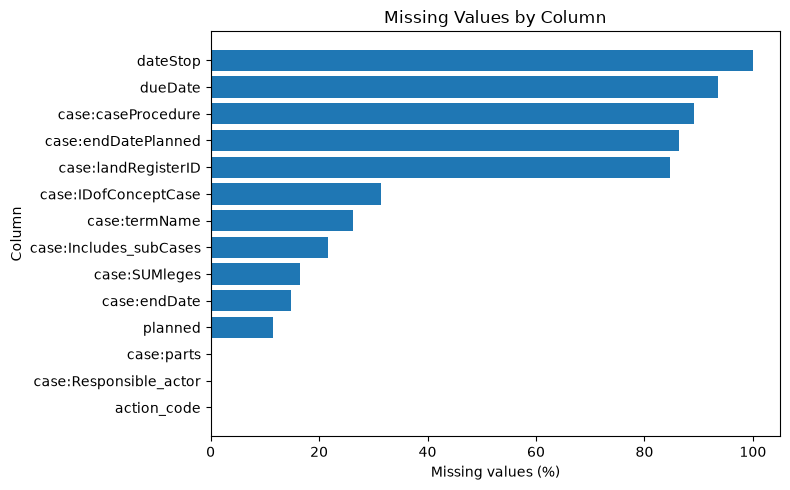

In [12]:
plt.figure(figsize=(8, 5))
plt.barh(missing_table.index, missing_table["missing_pct"])
plt.title("Missing Values by Column")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

This chart shows which columns contain missing values and the percentage of missing observations in each column.
Several optional fields have substantial missingness, while the main process fields used in this analysis are complete.
Some columns have only a few missing values (for example `action_code` has just one), so their bars are almost invisible.
As explained above, I kept these columns and did not remove any rows.

## 9. Preliminary EDA

I look at four simple questions:

1. How many events does a case have?
2. How long does a case last?
3. Which activities are the most common?
4. How are key case-level variables related?

### 9.1 Events per Case

In [13]:
events_per_case = df.groupby("case:concept:name").size()
events_per_case.describe()

count    1199.000000
mean       43.550459
std        16.988622
min         2.000000
25%        37.000000
50%        44.000000
75%        53.000000
max       101.000000
dtype: float64

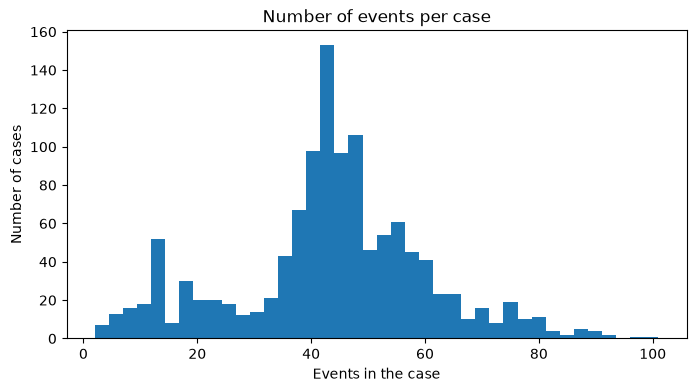

In [14]:
plt.figure(figsize=(8, 4))
plt.hist(events_per_case, bins=40)
plt.title("Number of events per case")
plt.xlabel("Events in the case")
plt.ylabel("Number of cases")
plt.show()

Cases contain different numbers of recorded process events. A typical case has about 44 events, but some have only
2 and the largest has about 100.

### 9.2 Case Duration

**Duration** = time between the **first** and the **last** recorded event of a case, in days.

I only use cases that have a recorded end date (`case:endDate` is not missing). For the other cases the process may have
continued after the data was collected, so their duration would be incomplete.

In [15]:
case_summary = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_summary["duration_days"] = (case_summary["last_event"] - case_summary["first_event"]).dt.total_seconds() / (24 * 60 * 60)

ended_cases = case_summary[case_summary["end_date"].notna()]
print("Cases with a recorded end date:", len(ended_cases))
ended_cases["duration_days"].describe()

Cases with a recorded end date: 956


count     956.000000
mean       98.127095
std       117.416488
min         1.433333
25%        47.422734
50%        63.000000
75%       102.533429
max      1486.000000
Name: duration_days, dtype: float64

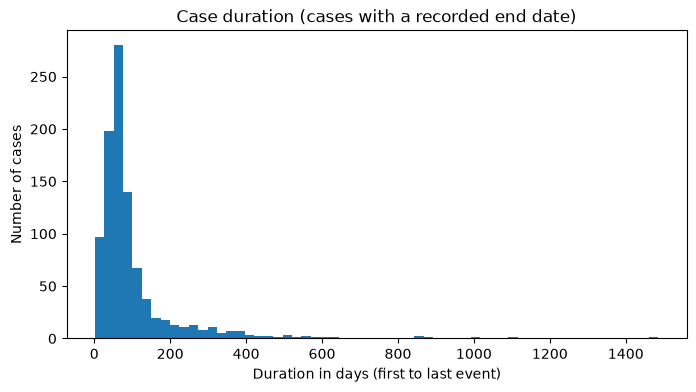

In [16]:
plt.figure(figsize=(8, 4))
plt.hist(ended_cases["duration_days"], bins=60)
plt.title("Case duration (cases with a recorded end date)")
plt.xlabel("Duration in days (first to last event)")
plt.ylabel("Number of cases")
plt.show()

Case durations vary considerably, and some cases take much longer than the typical case. The median case lasts about
63 days, but a long tail of cases runs for many months or even years. Because of this tail the mean (about 98 days) is
higher than the median, so the distribution is **right-skewed**.

### 9.3 Most Common Activities

In [17]:
top_activities = df["activityNameEN"].value_counts().head(10)
top_activities

activityNameEN
send confirmation receipt                       2074
procedure change                                1752
enter senddate decision environmental permit    1397
request complete                                1267
register submission date request                1199
phase application received                      1199
forward to the competent authority              1179
regular procedure without MER                   1161
enter senddate acknowledgement                  1057
phase application receptive                      940
Name: count, dtype: int64

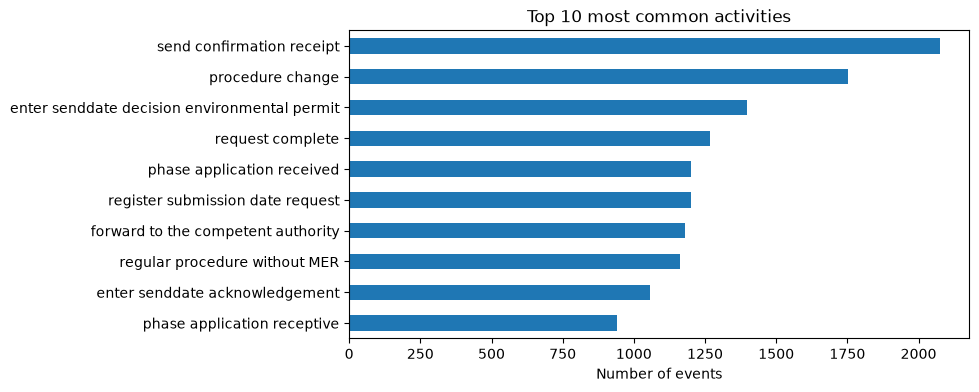

In [18]:
plt.figure(figsize=(8, 4))
top_activities.sort_values().plot(kind="barh")
plt.title("Top 10 most common activities")
plt.xlabel("Number of events")
plt.ylabel("")
plt.show()

Some administrative activities occur much more frequently than others. Steps like "register submission date request"
happen once in every case (1,199 times), while "send confirmation receipt" can happen more than once in the same case.

### 9.4 Correlation Heatmap of Key Case-Level Variables

Most columns in the event log are text (IDs, activity names), so a correlation of all 29 columns would not make sense.
Instead I make a small table with **one row per case** and four numeric variables:

- `events_per_case`: number of events in the case
- `unique_activities`: number of different activities (`concept:name`) in the case
- `unique_resources`: number of different resources (`org:resource`) in the case
- `duration_days`: the same duration as in 9.2 (first to last event)

I use the same **cases with a recorded end date** as in 9.2, so every case has a complete duration.

In [19]:
case_level = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
)
case_level = case_level.loc[ended_cases.index]          # same ended cases as in 9.2
case_level["duration_days"] = ended_cases["duration_days"]
print("Cases used:", len(case_level))

correlation = case_level.corr()
correlation.round(2)

Cases used: 956


,events_per_case,unique_activities,unique_resources,duration_days
events_per_case,1.00,0.99,0.38,0.41
unique_activities,0.99,1.00,0.36,0.39
unique_resources,0.38,0.36,1.00,0.06
duration_days,0.41,0.39,0.06,1.00


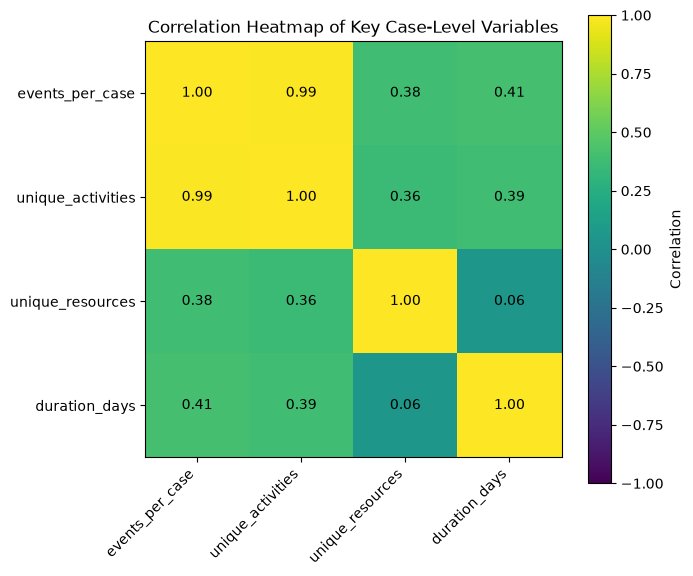

In [20]:
plt.figure(figsize=(7, 6))
plt.imshow(correlation, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.columns)), correlation.columns)

# write the correlation value in each square
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("Correlation Heatmap of Key Case-Level Variables")
plt.tight_layout()
plt.show()

The heatmap shows the linear relationships between the selected case-level variables. A positive value means that the
variables tend to increase together, while a value closer to zero indicates a weaker linear relationship.

- Cases with more events also tend to contain more unique activities (correlation 0.99).
- Duration has a moderate positive correlation with the number of events (0.41), but almost no linear relationship with the number of unique resources (0.06).

Correlation is not causation: these values only show which variables tend to move together.

## 10. Main Findings

- The dataset contains **52,217 events across 1,199 cases** (October 2010 – July 2015).
- Cases contain **different numbers of process events** (from 2 to 101, typically around 44).
- **Case duration varies considerably**: the median is about 63 days, but some cases take years.
- **Some activities are much more common** than others.
- The **core event-log fields** (case, activity, timestamp, resource) are complete and there are no duplicate rows, so they are usable for continued analysis.

## 11. Limitations

- Data from **one Dutch municipality** only.
- **Historical data** from about 2010–2015; the process may have changed since.
- **2010 and 2015 are partial years** (the data starts in October 2010 and ends in July 2015).
- Some **optional fields have many missing values**.
- Some fields are **not fully documented** in the source.
- This is an **external dataset, not SPAR data**, so results cannot automatically be generalised to Montenegro or SPAR.

## 12. Is the Dataset Suitable?

**Yes.** The dataset contains what my project question needs:

- case identifiers;
- activities;
- timestamps;
- resource identifiers;
- the process history of each case;
- the information needed to calculate case duration.

**However, its predictive usefulness has not been tested yet.** Whether early information really helps to identify longer
cases will be checked in later Capstone stages.

## 13. Next Steps

- Define a clear target (what counts as "taking longer than usual").
- Create simple features from information available early in each case.
- Test classification or regression methods taught in the course.